# DCIT 316 Final Project - Misinformation Detection
## EDA and Baseline Model
Dataset: Fake and Real News Dataset (ISOT), Kaggle

In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option('display.max_colwidth', 100)

print("Current working directory:", os.getcwd())

Current working directory: C:\Users\jessy\OneDrive - University of Ghana\Documents\L300 SEM2\DCIT316\Sem-Project\zunuo_dcit316-final-project\src


In [6]:
fake = pd.read_csv('../data/raw/Fake.csv')
true = pd.read_csv('../data/raw/True.csv')

fake['label'] = 'fake'
true['label'] = 'real'

df = pd.concat([fake, true], ignore_index=True)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)  # shuffle

print(df.shape)
df.head()

(44898, 5)


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committed a ‘Coup d’état’ Against the Constitution,"21st Century Wire says Ben Stein, reputable professor from, Pepperdine University (also of some ...",US_News,"February 13, 2017",fake
1,Trump drops Steve Bannon from National Security Council,WASHINGTON (Reuters) - U.S. President Donald Trump removed his chief strategist Steve Bannon fro...,politicsNews,"April 5, 2017",real
2,Puerto Rico expects U.S. to lift Jones Act shipping restrictions,(Reuters) - Puerto Rico Governor Ricardo Rossello said on Wednesday he expected the federal gove...,politicsNews,"September 27, 2017",real
3,OOPS: Trump Just Accidentally Confirmed He Leaked Israeli Intelligence To Russia (VIDEO),"On Monday, Donald Trump once again embarrassed himself and his country by accidentally revealing...",News,"May 22, 2017",fake
4,Donald Trump heads for Scotland to reopen a golf resort,"GLASGOW, Scotland (Reuters) - Most U.S. presidential candidates go abroad to sharpen their forei...",politicsNews,"June 24, 2016",real


label
fake    23481
real    21417
Name: count, dtype: int64


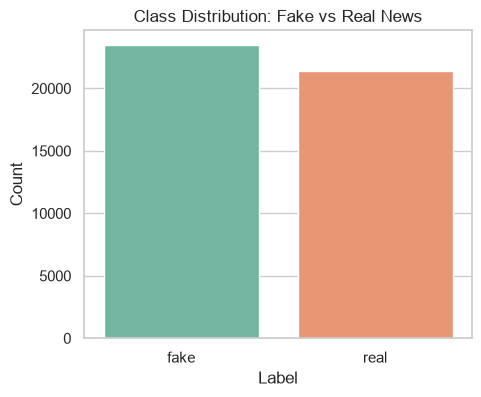

In [7]:
class_counts = df['label'].value_counts()
print(class_counts)

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x='label', hue='label', palette='Set2', legend=False)
plt.title('Class Distribution: Fake vs Real News')
plt.xlabel('Label')
plt.ylabel('Count')
plt.savefig('../reports/figures/class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

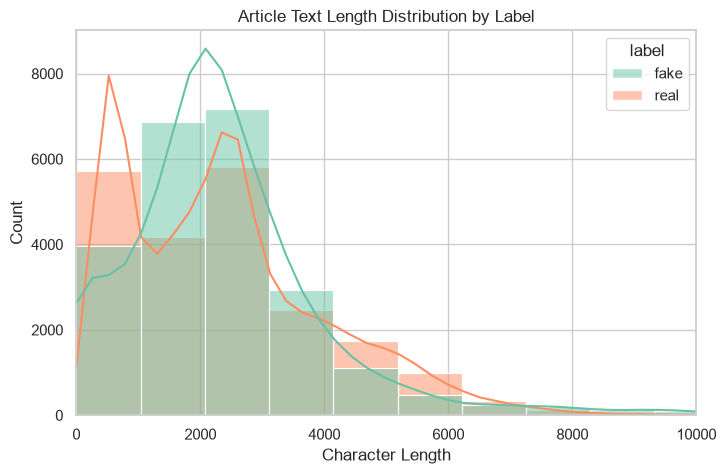

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
fake,23481.0,2547.396235,2532.884399,1.0,1433.0,2166.0,3032.0,51794.0
real,21417.0,2383.278517,1684.835730,1.0,914.0,2222.0,3237.0,29781.0


In [8]:
df['text_length'] = df['text'].astype(str).apply(len)

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='text_length', hue='label', bins=50, kde=True, palette='Set2')
plt.title('Article Text Length Distribution by Label')
plt.xlabel('Character Length')
plt.xlim(0, 10000)
plt.savefig('../reports/figures/text_length_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

df.groupby('label')['text_length'].describe()

subject
politicsNews       11272
worldnews          10145
News                9050
politics            6841
left-news           4459
Government News     1570
US_News              783
Middle-east          778
Name: count, dtype: int64


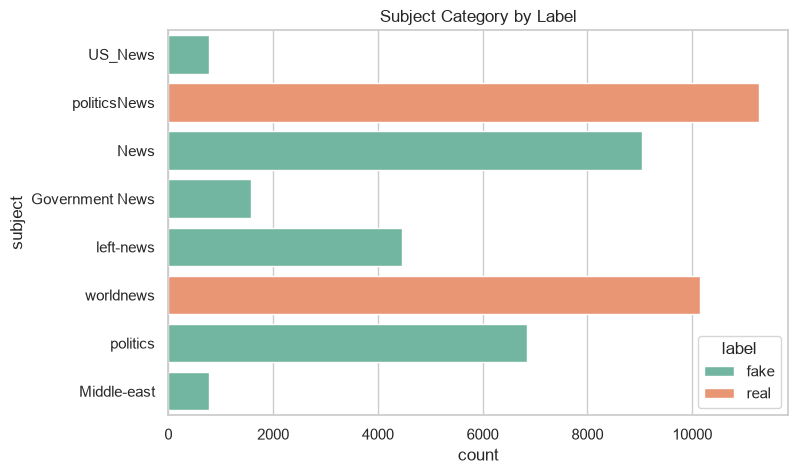


Subjects with more than one label (should be empty if leak is total):
Series([], Name: label, dtype: int64)


In [9]:
print(df['subject'].value_counts())

plt.figure(figsize=(8, 5))
sns.countplot(data=df, y='subject', hue='label', palette='Set2')
plt.title('Subject Category by Label')
plt.savefig('../reports/figures/subject_by_label.png', dpi=150, bbox_inches='tight')
plt.show()

# Confirm subject perfectly leaks label
leak_check = df.groupby('subject')['label'].nunique()
print("\nSubjects with more than one label (should be empty if leak is total):")
print(leak_check[leak_check > 1])

In [10]:
short_text_count = (df['text_length'] < 20).sum()
print(f"Rows with text shorter than 20 characters: {short_text_count}")

df_clean = df[df['text_length'] >= 20].copy()
print(f"Original rows: {len(df)}")
print(f"Rows after cleaning: {len(df_clean)}")
print(f"Rows dropped: {len(df) - len(df_clean)}")

Rows with text shorter than 20 characters: 670
Original rows: 44898
Rows after cleaning: 44228
Rows dropped: 670


In [11]:
# Combine title and text into a single text field for modeling
df_clean['full_text'] = df_clean['title'].astype(str) + ' ' + df_clean['text'].astype(str)

# Explicitly confirm which columns we use vs exclude for modeling
print("Columns available:", df_clean.columns.tolist())
print("\nFeature used for modeling: 'full_text' (title + text combined)")
print("Target: 'label'")
print("\nExcluded from modeling: 'subject' (confirmed label leak), 'date' (not predictive of content)")

df_clean[['full_text', 'label']].head()

Columns available: ['title', 'text', 'subject', 'date', 'label', 'text_length', 'full_text']

Feature used for modeling: 'full_text' (title + text combined)
Target: 'label'

Excluded from modeling: 'subject' (confirmed label leak), 'date' (not predictive of content)


,full_text,label
0,Ben Stein Calls Out 9th Circuit Court: Committed a ‘Coup d’état’ Against the Constitution 21st C...,fake
1,Trump drops Steve Bannon from National Security Council WASHINGTON (Reuters) - U.S. President Do...,real
2,Puerto Rico expects U.S. to lift Jones Act shipping restrictions (Reuters) - Puerto Rico Governo...,real
3,OOPS: Trump Just Accidentally Confirmed He Leaked Israeli Intelligence To Russia (VIDEO) On Mon...,fake
4,"Donald Trump heads for Scotland to reopen a golf resort GLASGOW, Scotland (Reuters) - Most U.S. ...",real


In [12]:
from sklearn.model_selection import train_test_split

X = df_clean['full_text']
y = df_clean['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")
print(f"\nTraining label distribution:\n{y_train.value_counts(normalize=True)}")
print(f"\nTest label distribution:\n{y_test.value_counts(normalize=True)}")


Training set size: 35382
Test set size: 8846

Training label distribution:
label
fake    0.515771
real    0.484229
Name: proportion, dtype: float64

Test label distribution:
label
fake    0.515826
real    0.484174
Name: proportion, dtype: float64


In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Vectorize
tfidf = TfidfVectorizer(max_features=10000, stop_words='english')
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f"TF-IDF training matrix shape: {X_train_tfidf.shape}")
print(f"TF-IDF test matrix shape: {X_test_tfidf.shape}")

# Train baseline model
baseline_model = LogisticRegression(max_iter=1000, random_state=42)
baseline_model.fit(X_train_tfidf, y_train)

print("\nBaseline model trained.")

TF-IDF training matrix shape: (35382, 10000)
TF-IDF test matrix shape: (8846, 10000)

Baseline model trained.


Accuracy: 0.9868
Macro F1: 0.9868

Classification Report:
              precision    recall  f1-score   support

        fake       0.99      0.98      0.99      4563
        real       0.98      0.99      0.99      4283

    accuracy                           0.99      8846
   macro avg       0.99      0.99      0.99      8846
weighted avg       0.99      0.99      0.99      8846



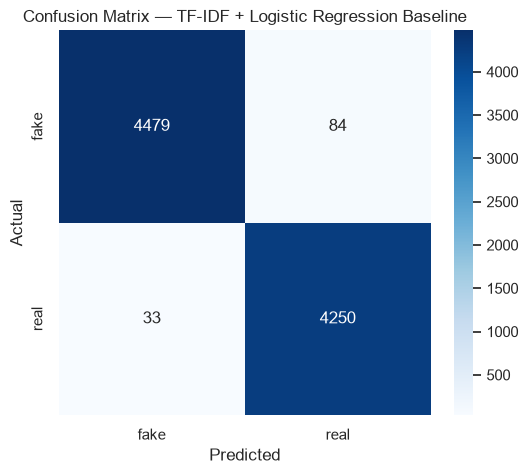

In [14]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

y_pred_baseline = baseline_model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred_baseline)
macro_f1 = f1_score(y_test, y_pred_baseline, average='macro')

print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_baseline))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_baseline, labels=baseline_model.classes_)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=baseline_model.classes_,
            yticklabels=baseline_model.classes_)
plt.title('Confusion Matrix — TF-IDF + Logistic Regression Baseline')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.savefig('../reports/figures/baseline_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

In [15]:
reuters_check = df_clean['text'].str.contains(r'\(Reuters\)', regex=True, na=False)
print(df_clean.groupby('label').apply(lambda x: x['text'].str.contains(r'\(Reuters\)', regex=True, na=False).mean()))

label
fake    0.000395
real    0.992109
dtype: float64


In [16]:
import re

def strip_dateline_artifact(text):
    # Removes patterns like "WASHINGTON (Reuters) - " or "LONDON (Reuters) -"
    # which appear near the start of most real articles
    cleaned = re.sub(r'^[A-Z\s,]+\(Reuters\)\s*-\s*', '', str(text))
    # Also catch (Reuters) appearing anywhere else in the text
    cleaned = re.sub(r'\(Reuters\)', '', cleaned)
    return cleaned

df_clean['text_stripped'] = df_clean['text'].apply(strip_dateline_artifact)
df_clean['full_text_stripped'] = df_clean['title'].astype(str) + ' ' + df_clean['text_stripped'].astype(str)

# Verify the artifact is gone
remaining = df_clean['full_text_stripped'].str.contains(r'\(Reuters\)', regex=True, na=False).sum()
print(f"Rows still containing '(Reuters)' after stripping: {remaining}")

df_clean[['full_text_stripped']].head()

Rows still containing '(Reuters)' after stripping: 0


,full_text_stripped
0,Ben Stein Calls Out 9th Circuit Court: Committed a ‘Coup d’état’ Against the Constitution 21st C...
1,Trump drops Steve Bannon from National Security Council U.S. President Donald Trump removed his ...
2,Puerto Rico expects U.S. to lift Jones Act shipping restrictions - Puerto Rico Governor Ricardo...
3,OOPS: Trump Just Accidentally Confirmed He Leaked Israeli Intelligence To Russia (VIDEO) On Mon...
4,"Donald Trump heads for Scotland to reopen a golf resort GLASGOW, Scotland - Most U.S. president..."


In [17]:
X_stripped = df_clean['full_text_stripped']
y_stripped = df_clean['label']

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_stripped, y_stripped, test_size=0.2, random_state=42, stratify=y_stripped
)

tfidf_stripped = TfidfVectorizer(max_features=10000, stop_words='english')
X_train_s_tfidf = tfidf_stripped.fit_transform(X_train_s)
X_test_s_tfidf = tfidf_stripped.transform(X_test_s)

stripped_model = LogisticRegression(max_iter=1000, random_state=42)
stripped_model.fit(X_train_s_tfidf, y_train_s)

print("Stripped-text model trained.")

Stripped-text model trained.


Stripped-text Accuracy: 0.9800
Stripped-text Macro F1: 0.9800

Classification Report (stripped):
              precision    recall  f1-score   support

        fake       0.99      0.97      0.98      4563
        real       0.97      0.99      0.98      4283

    accuracy                           0.98      8846
   macro avg       0.98      0.98      0.98      8846
weighted avg       0.98      0.98      0.98      8846


--- Comparison ---
Original (with artifact) — Accuracy: 0.9868, Macro F1: 0.9868
Stripped (artifact removed) — Accuracy: 0.9800, Macro F1: 0.9800
Accuracy drop: 0.0068


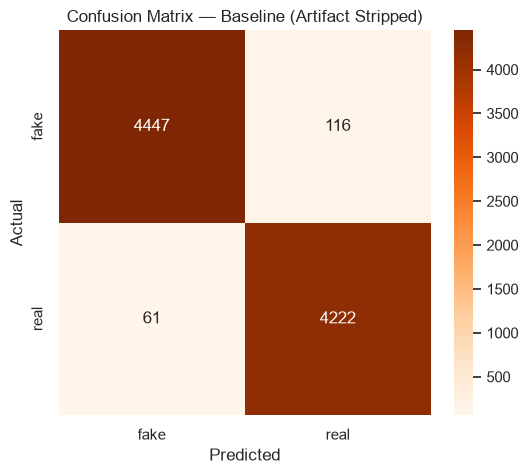

In [18]:
y_pred_stripped = stripped_model.predict(X_test_s_tfidf)

accuracy_stripped = accuracy_score(y_test_s, y_pred_stripped)
macro_f1_stripped = f1_score(y_test_s, y_pred_stripped, average='macro')

print(f"Stripped-text Accuracy: {accuracy_stripped:.4f}")
print(f"Stripped-text Macro F1: {macro_f1_stripped:.4f}")
print("\nClassification Report (stripped):")
print(classification_report(y_test_s, y_pred_stripped))

print(f"\n--- Comparison ---")
print(f"Original (with artifact) — Accuracy: {accuracy:.4f}, Macro F1: {macro_f1:.4f}")
print(f"Stripped (artifact removed) — Accuracy: {accuracy_stripped:.4f}, Macro F1: {macro_f1_stripped:.4f}")
print(f"Accuracy drop: {accuracy - accuracy_stripped:.4f}")

cm_stripped = confusion_matrix(y_test_s, y_pred_stripped, labels=stripped_model.classes_)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_stripped, annot=True, fmt='d', cmap='Oranges',
            xticklabels=stripped_model.classes_,
            yticklabels=stripped_model.classes_)
plt.title('Confusion Matrix — Baseline (Artifact Stripped)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.savefig('../reports/figures/stripped_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()